# Sun's Blessing (Templar)

Sun's Blessing is a free self-buff. For 180 s it adds the same bonus to all five attributes,
to armor and to weapon value. The cooldown is 55 s, but a recast simply refreshes the existing
buff, so the uptime is 100%.

**Rebalanced.** The bonus was `clamp(3(p_u/10 + 2), 3, 90)`, which hit +90 at unbuffed skill 280.
It now uses `skill_knee_300(p_u, 6, 90)` (`suns_blessing_bonus`): +6 at skill 0, +90 at skill 300,
then half that slope up to a hard limit of +120 at skill 515. The limit keeps `armor[1]` and
`weapon[1]` inside their `i8` range. The dotted "before" curves below show the old formula.

| | |
|---|---|
| Class | Templar |
| Target | Self only |
| Cost | none |
| Cooldown | 55 s (separate `SK_SUNS_BLESSING` marker) |
| Landing roll | none |
| Duration | 180 s |
| Effect | `attrib[0..5][1]`, `armor[1]`, `weapon[1]` += `min(skill_knee_300(p_u, 6, 90), 120)` |
| Power | `unbuffed_skill_power`: the modified skill minus the part contributed by spell attribute bonuses |
| Source | `server/src/driver/skill/templar.rs::suns_blessing_bonus`, `skill_suns_blessing`; `driver/skill/common.rs::unbuffed_skill_power`, `skill_knee_300` |

---

# Formula

$$
\text{bonus} = \min\!\left(120,\ \begin{cases}
6 + \left\lfloor \tfrac{84\,p_u}{300} \right\rfloor & p_u \le 300 \\[4pt]
90 + \left\lfloor \tfrac{84(p_u - 300)}{600} \right\rfloor & p_u > 300
\end{cases}\right)
$$

$p_u$ is the *unbuffed* power: the modified skill with every active spell's attribute bonus
removed from the skill's three governing attributes. Without this, the buff's own +bonus to
attributes would feed back into the next recast.

$$
p_u = p - \left(\left\lfloor \tfrac{\sum a_5}{5} \right\rfloor - \left\lfloor \tfrac{\max(0,\ \sum (a_5 - a_\text{spell}))}{5} \right\rfloor\right)
$$

Each skill is derived from three attributes divided by 5, so +bonus to every attribute is worth
about $\tfrac{3}{5}\,\text{bonus}$ on **every** skill.

| Quantity | Now | Before |
|---|---|---|
| Floor | +6 at $p_u = 0$ | +6 at $p_u = 0$ |
| Slope to 300 | +2.8 per 10 skill points | +3 per 10 to skill 280 |
| Raise cap ($p_u$ 105 / 120) | +35 / +39 | +36 / +42 |
| Endgame ($p_u$ 275 / 300) | +83 / +90 | +87 / +90 |
| Beyond 300 | +1.4 per 10 (+97 at 350, +111 at 450) | +90 |
| Hard limit | +120 from $p_u \ge 515$ | +90 from $p_u \ge 280$ |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
BUFF_S = 180
COOLDOWN_S = 55

# Model

In [2]:
MAX_BONUS = 120


def sun_bonus(p_unbuffed):
    return np.minimum(mm.knee_300(p_unbuffed, 6, 90), MAX_BONUS)


# Before the mod-300 knee: +3 per 10 points, capped at +90 from skill 280.
def old_sun_bonus(p_unbuffed):
    return mm.clamp((mm.idiv(p_unbuffed, 10) + 2) * 3, 3, 90)


def unbuffed_skill_power(skill5, attribs5, spell_bonus):
    """`unbuffed_skill_power` for one skill: attribs5 / spell_bonus are its three attributes."""
    buffed = sum(attribs5)
    base = sum(a - s for a, s in zip(attribs5, spell_bonus))
    return skill5 - (buffed // 5 - max(0, base) // 5)


def incoming_reduction(p, wv, base_armor=20, strength=80, bonus=sun_bonus):
    """Fraction of one attacker's per-hit damage removed by the armor bonus."""
    b = bonus(p)
    before = mm.melee_hit_hp(wv, strength, base_armor)
    after = mm.melee_hit_hp(wv, strength, base_armor + np.asarray(b))
    return 1 - after / before


def outgoing_gain(p, wv, strength=80, armor=20, bonus=sun_bonus):
    """Per-hit damage multiplier from +bonus weapon value and +bonus STR."""
    b = np.atleast_1d(bonus(p))
    after = np.array([mm.melee_hit_hp(wv + x, strength + x, armor) for x in b])
    out = after / mm.melee_hit_hp(wv, strength, armor)
    return mm._scalar(out if np.ndim(p) else out[0])

# Validation

- `suns_blessing_grants_bonuses_and_a_separate_cooldown`: power 40 gives +17 to every attribute,
  armor and weapon. The buff lasts `TICKS*180`, the cooldown `TICKS*55`, and a recast during the
  cooldown keeps the same item.
- `suns_blessing_bonus_is_capped`: power 1000 gives armor +120.
- `templar_bonuses_reach_their_design_value_at_skill_300`: `suns_blessing_bonus` 0 → 6,
  300 → 90, 450 → 111, 2000 → 120.
- `unbuffed_skill_power_strips_spell_attribute_bonuses`: skill 69 with attributes at 65 stays 69.
  With +15 from a spell on each attribute it becomes 60.

In [3]:
assert sun_bonus(40) == 17 and sun_bonus(1000) == 120
assert [int(sun_bonus(p)) for p in (0, 300, 450, 2000)] == [6, 90, 111, 120]
assert [int(sun_bonus(p)) for p in (105, 120, 275, 350, 514, 515)] == [35, 39, 83, 97, 119, 120]
assert mm.TICKS * BUFF_S == 6480 and mm.TICKS * COOLDOWN_S == 1980
assert unbuffed_skill_power(69, (65, 65, 65), (0, 0, 0)) == 69
assert unbuffed_skill_power(69, (65, 65, 65), (15, 15, 15)) == 60
assert old_sun_bonus(105) == 36 and old_sun_bonus(120) == 42 and old_sun_bonus(280) == 90
print("Sun's Blessing model OK")

Sun's Blessing model OK


# Plots

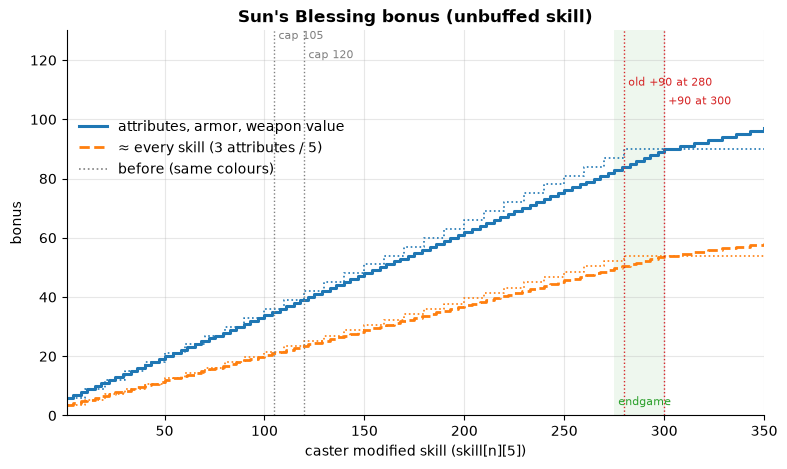

In [4]:
fig, ax = plt.subplots()
line, = ax.step(P, sun_bonus(P), where="post", lw=2.2, label="attributes, armor, weapon value")
ax.step(P, old_sun_bonus(P), where="post", color=line.get_color(), lw=1.2, ls=":")
line, = ax.step(P, sun_bonus(P) * 3 / 5, where="post", ls="--", label="≈ every skill (3 attributes / 5)")
ax.step(P, old_sun_bonus(P) * 3 / 5, where="post", color=line.get_color(), lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "bonus", "Sun's Blessing bonus (unbuffed skill)")
mm.mark_caps(ax, extra=[(280, "old +90 at 280"), (mm.SKILL_KNEE, "+90 at 300")])
ax.set_ylim(0, 130)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.8))

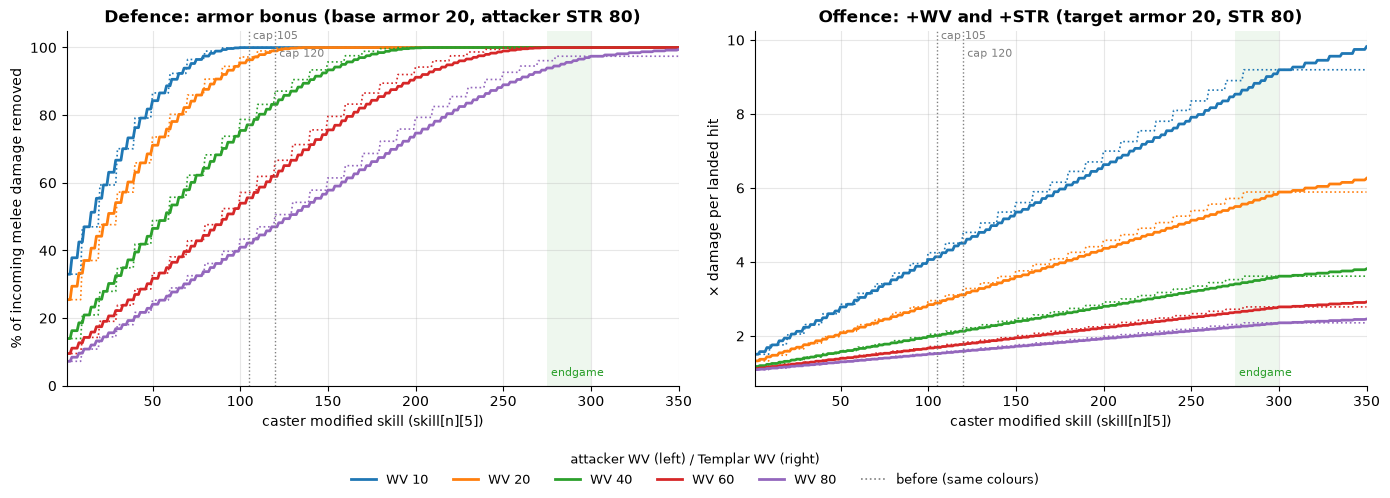

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for wv in mm.WV_SWEEP:
    line, = ax.plot(P, 100 * incoming_reduction(P, wv), label=f"WV {wv}")
    ax.plot(P, 100 * incoming_reduction(P, wv, bonus=old_sun_bonus), color=line.get_color(), lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "% of incoming melee damage removed", "Defence: armor bonus (base armor 20, attacker STR 80)")
ax.set_ylim(0, 105)
mm.mark_caps(ax)

ax = axes[1]
for wv in mm.WV_SWEEP:
    line, = ax.plot(P, outgoing_gain(P, wv))
    ax.plot(P, outgoing_gain(P, wv, bonus=old_sun_bonus), color=line.get_color(), lw=1.2, ls=":")
mm.skill_axis(ax, "× damage per landed hit", "Offence: +WV and +STR (target armor 20, STR 80)")
mm.mark_caps(ax)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=6, fontsize=9,
           title="attacker WV (left) / Templar WV (right)", title_fontsize=9)
plt.tight_layout(rect=(0, 0.1, 1, 1))

# Observations

- The bonus reaches +90 at unbuffed skill 300 instead of 280, and keeps growing beyond at half
  slope (+97 at 350, +111 at 450) up to +120 at 515. It passes the old +90 ceiling from skill 308,
  so unlike the other knee abilities Sun's Blessing is stronger at and beyond the endgame than
  before, not weaker.
- The mid-game barely changes: +35 at skill 105 (before +36) and +39 at 120 (before +42). That is
  about +21 to every skill, including Weapon Skill, Resist and Immunity. It costs nothing, lasts
  180 s, and can be refreshed after 55 s. `add_spell` replaces a same-temp spell unless the new
  one is weaker, and an equal-power recast is not weaker, so the uptime is 100%.
- Against base armor 20 at skill 105, the armor bonus removes 77% of a WV-40 STR-80 attacker's
  damage per hit and 56% of a WV-60 attacker's. The bonus fully nullifies WV-20 attackers from
  skill 140, WV-40 from 211 and WV-60 from 283 (before 130, 200 and 270). WV-80 attackers are
  nullified from 408, which the old +90 ceiling never reached.
- +WV and +STR multiply a WV-40 Templar's damage per landed hit against armor 20 by ×2.01 at
  skill 105 (10.75 → 21.6 HP) and ×3.62 at 300 (→ 38.9 HP). The +21 Weapon Skill at 105 also
  moves an even fight from 60% to 90% to hit (Δ +21 → chance 18) and drops the enemy from 60% to
  30%. At 300 the +54 Weapon Skill pins the table at 95% / 5%, and stacked with Inner Strength
  (+150) the Templar out-skills any opponent.
- The buff's own attribute bonus is stripped before the bonus is computed, so recasting does not
  compound. Other attribute buffs (Bless, Sun's Blessing itself) do not raise it either.
- The doc comment says the cooldown is "slightly shorter than the buff duration". The cooldown
  is 55 s against a 180 s buff, so the cooldown never limits anything.
- The knee makes the endgame problem worse. Options are to charge a resource, to shorten the buff
  below the cooldown (for example 45 s buff, 55 s cooldown), or to split the bonus so attributes,
  armor and weapon do not all scale with the same number. A third of the current bonus on armor
  and weapon, or a lower endgame target such as `skill_knee_300(p_u, 6, 60)`, would still be a
  strong buff.